# Imports & Setup

In [2]:
%matplotlib inline

import logging
import os
from datetime import datetime

import pandas as pd
from tqdm import tqdm

from metrics import MetricsContainer
from loading import load_experiment

from analytics.training import plot_models_together

log = logging.getLogger(__name__)

# Experiments Loading

In [3]:
log_root = "..\logs\ByModel"
output_dir = log_root
data = load_experiment(log_root, load="final")
log.info("Loaded data for %s model configurations.", len(data))

Loading experiment:  84%|████████▍ | 31/37 [00:08<00:01,  4.55it/s]Error loading metrics: Metrics file not found at ..\logs\ByModel\Quantum\vqm\VQM200\0\metrics\logger.pkl
Traceback (most recent call last):
  File "c:\Users\fwilh\Desktop\QB-PIER\src\metrics\MetricsContainer.py", line 177, in load_metrics
    raise FileNotFoundError(f"Metrics file not found at {pkl_path}")
FileNotFoundError: Metrics file not found at ..\logs\ByModel\Quantum\vqm\VQM200\0\metrics\logger.pkl
Loading experiment: 100%|██████████| 37/37 [00:09<00:00,  4.02it/s]


In [4]:
models = {}

for key, seed_dict in data.items():
    normalized = key.replace("/", os.sep).replace("\\", os.sep)
    parts = [p for p in normalized.split(os.sep) if p]
    if not parts: continue
    family = parts[0].strip().lower()
    architecture = parts[1].strip().lower() if len(parts) > 1 else ""
    variant = os.sep.join(parts[2:]) if len(parts) > 2 else ""
    
    models.setdefault(family, {}).setdefault(architecture, {})[variant] = seed_dict

len(models.get("classical", {})), len(models.get("hybrid", {})), len(models.get("quantum", {}))

(5, 6, 1)

### Manual Selections

In [5]:
classical_baselines = {
    "MLP": models['classical']['mlp']['hidden_sizes=[1024, 512, 64, 64]'],
    "ConvNet": models['classical']['convnet']['conv_channels=[32,64],fc_sizes=[128]'],
    "ResNet18": models['classical']['resnet18'][''],
    "MLP Mixer": models['classical']['mlpmixer']['']
}

hybrid_baselines = {
    "HPVQL": models['hybrid']['hpvql'][''],
    "HPVQM": models['hybrid']['hpvqm']['qblocks=5,qdepth=50'],
    "HQE": models['hybrid']['hqe'][''],
    "HQUANV": models['hybrid']['hquanv'][''],
    "HVQL": models['hybrid']['hvql']['ansatz=strong,qdepth=50'],
    "HVQM": models['hybrid']['hvqm']['ansatz=strong,qdepth=50']
}

# Training Figures

## Classical Figures

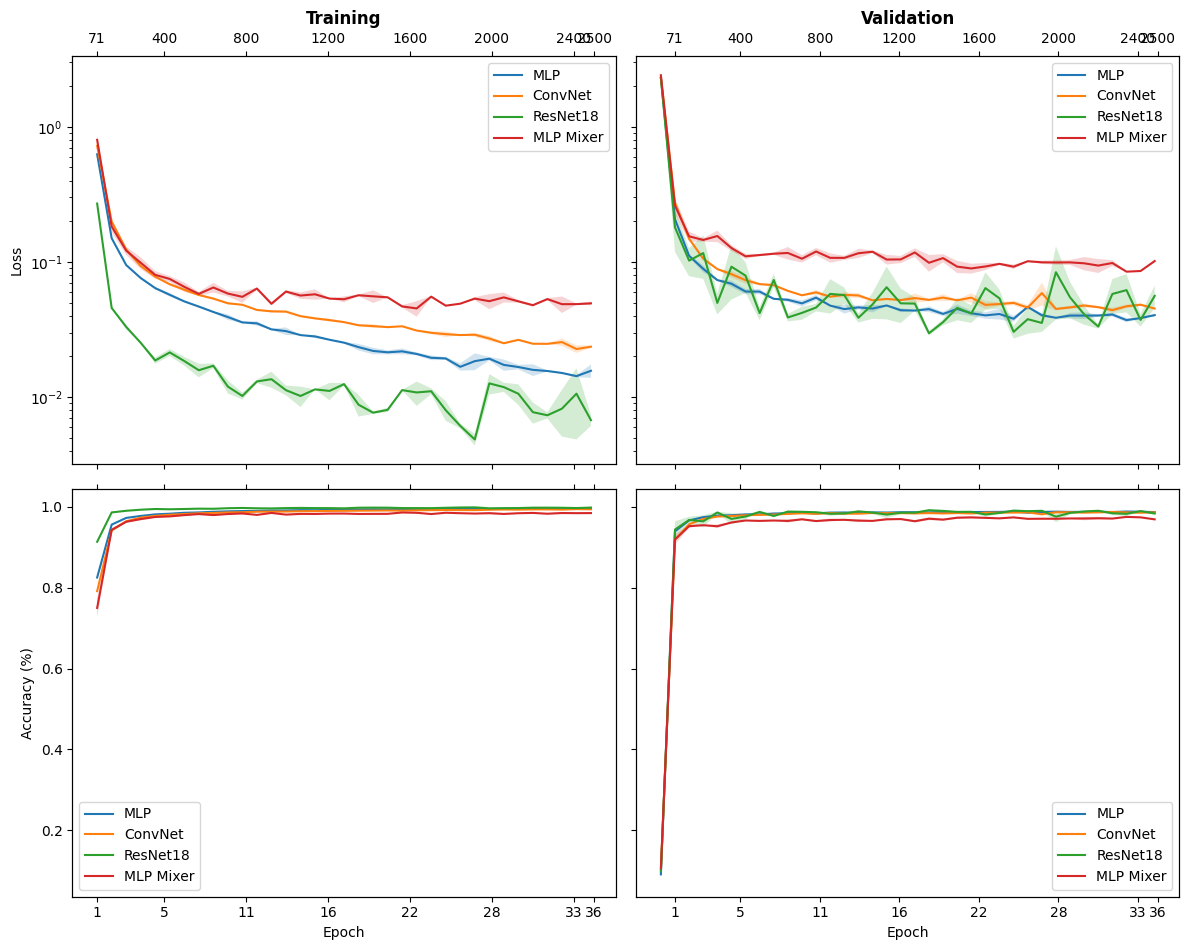

In [6]:
# Comparison of classical baselines
plot_models_together(classical_baselines, fig_dir=f"{output_dir}/classical", show=True)

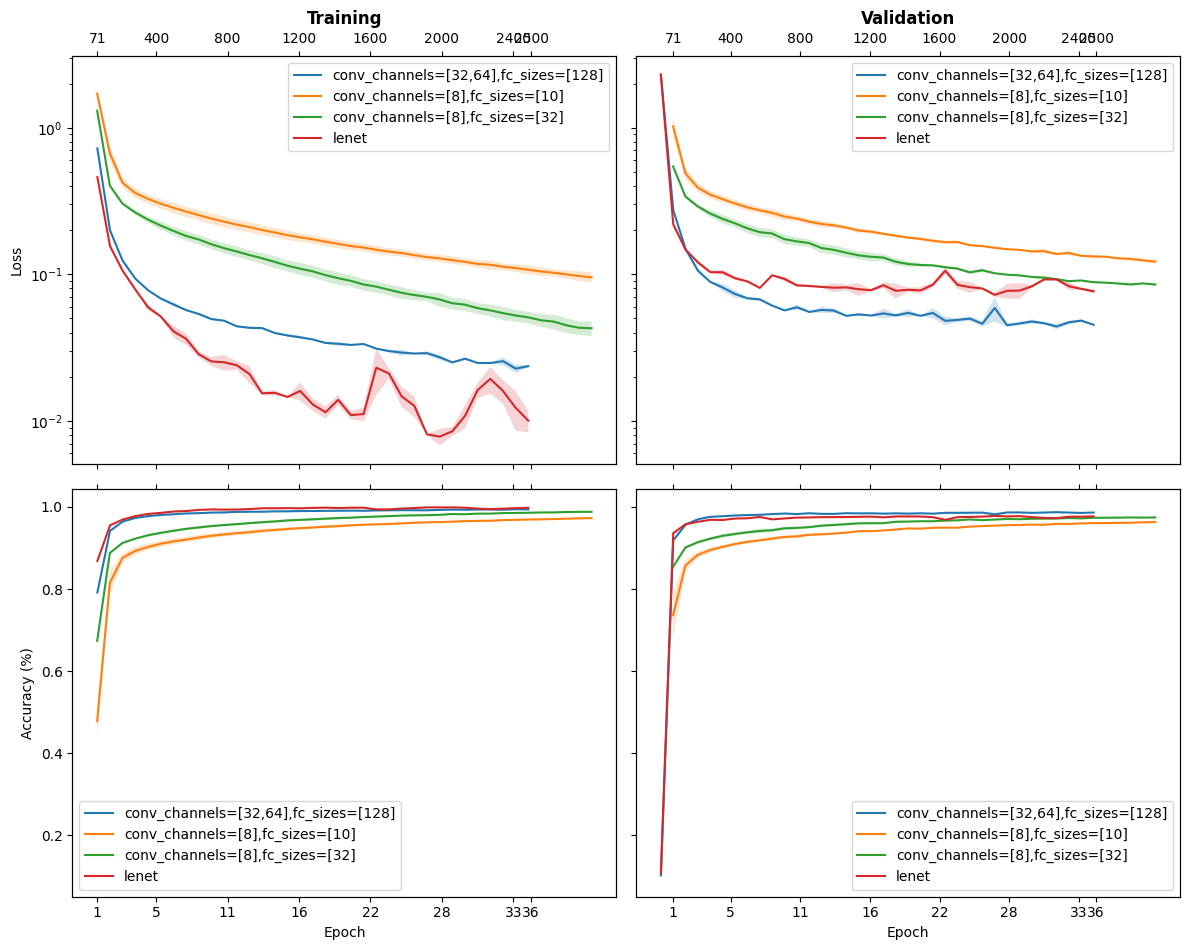

In [7]:
# ConvNet Variants

convnet_models = {}
convnet_models.update(models['classical']['convnet'])
convnet_models.update({'lenet':models['classical']['lenet']['']})

plot_models_together(convnet_models, fig_dir=f"{output_dir}/classical/convnet", show=True)

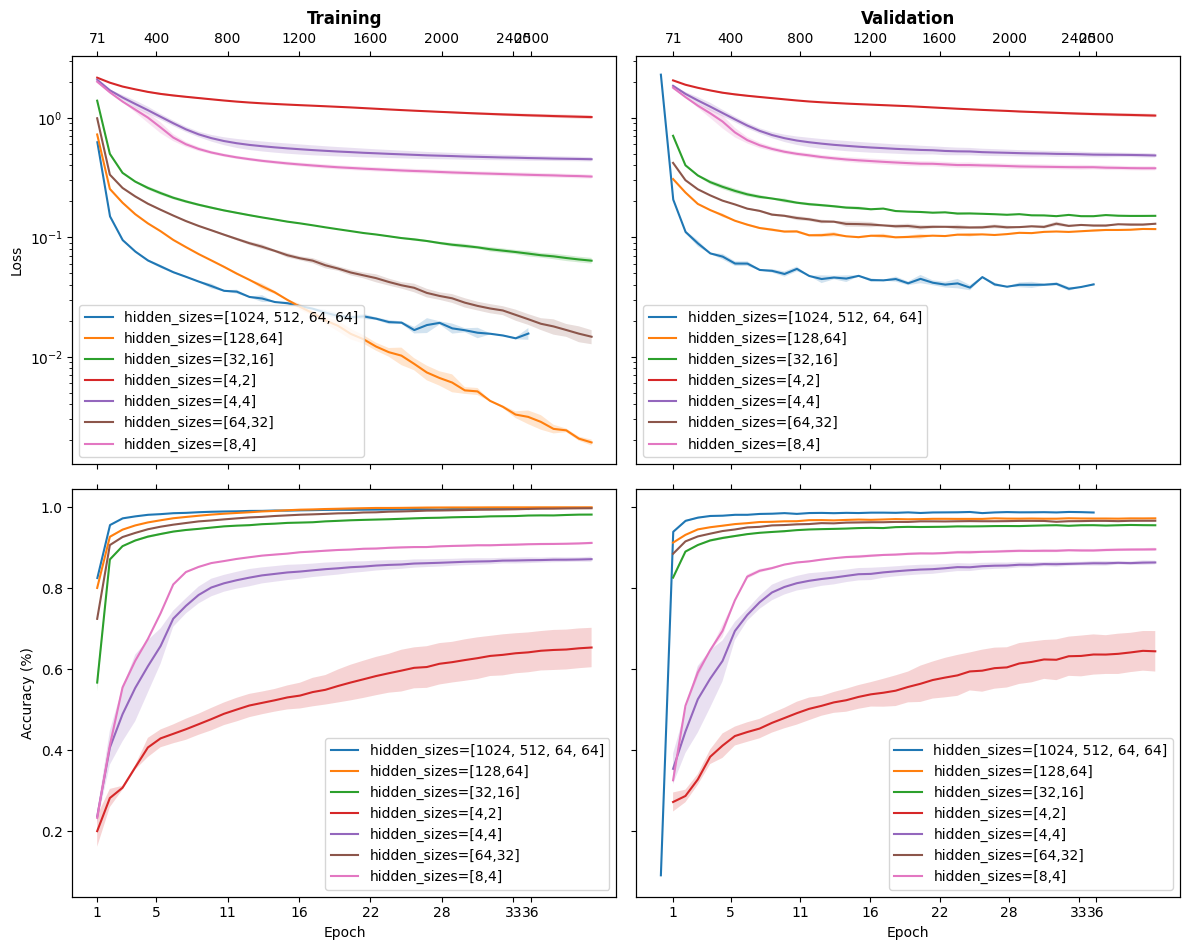

In [8]:
# Combine classical MLP and LeNet variants into one dict

plot_models_together(models['classical']['mlp'], fig_dir=f"{output_dir}/classical/mlp", show=True)

## Hybrid Figures

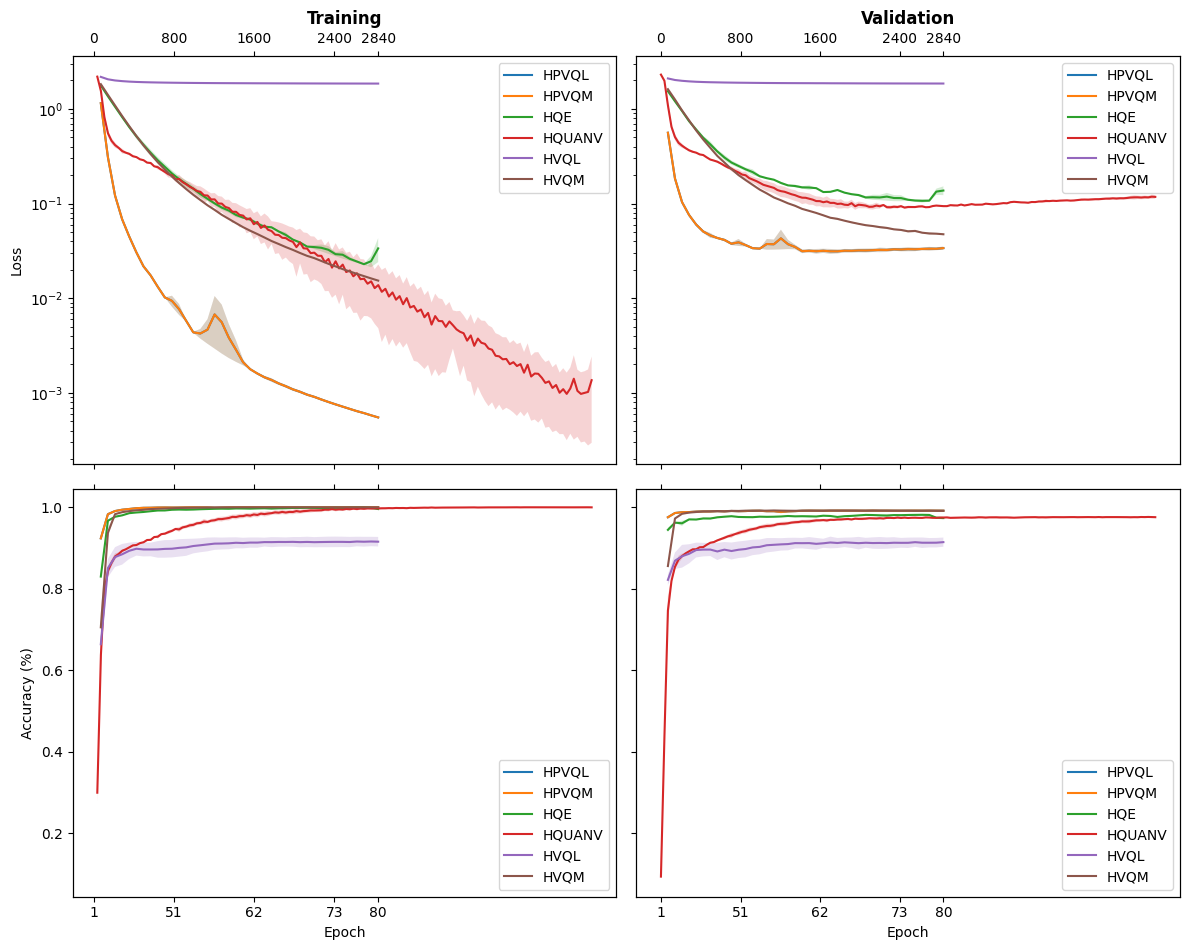

In [9]:
# Comparison of hybrid baselines
plot_models_together(hybrid_baselines, fig_dir=f"{output_dir}/hybrid", show=True)

In [16]:
hvql_no_basic = {k: v for k, v in models['hybrid']['hvql'].items() if "basic" not in k.lower()}

hvql_no_basic.keys()

dict_keys(['ansatz=random,qdepth=50', 'ansatz=strong,qdepth=50', 'dropout', 'residuals'])

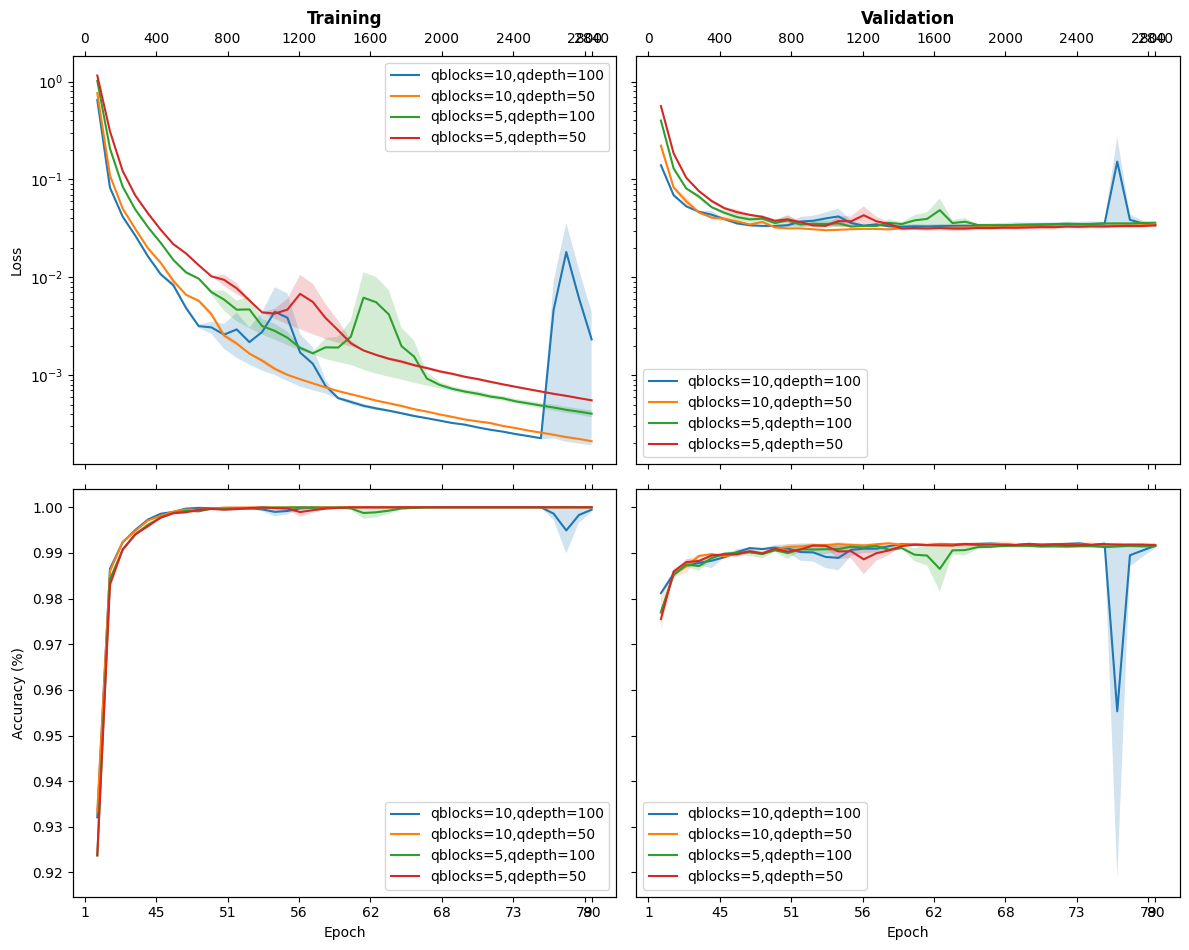

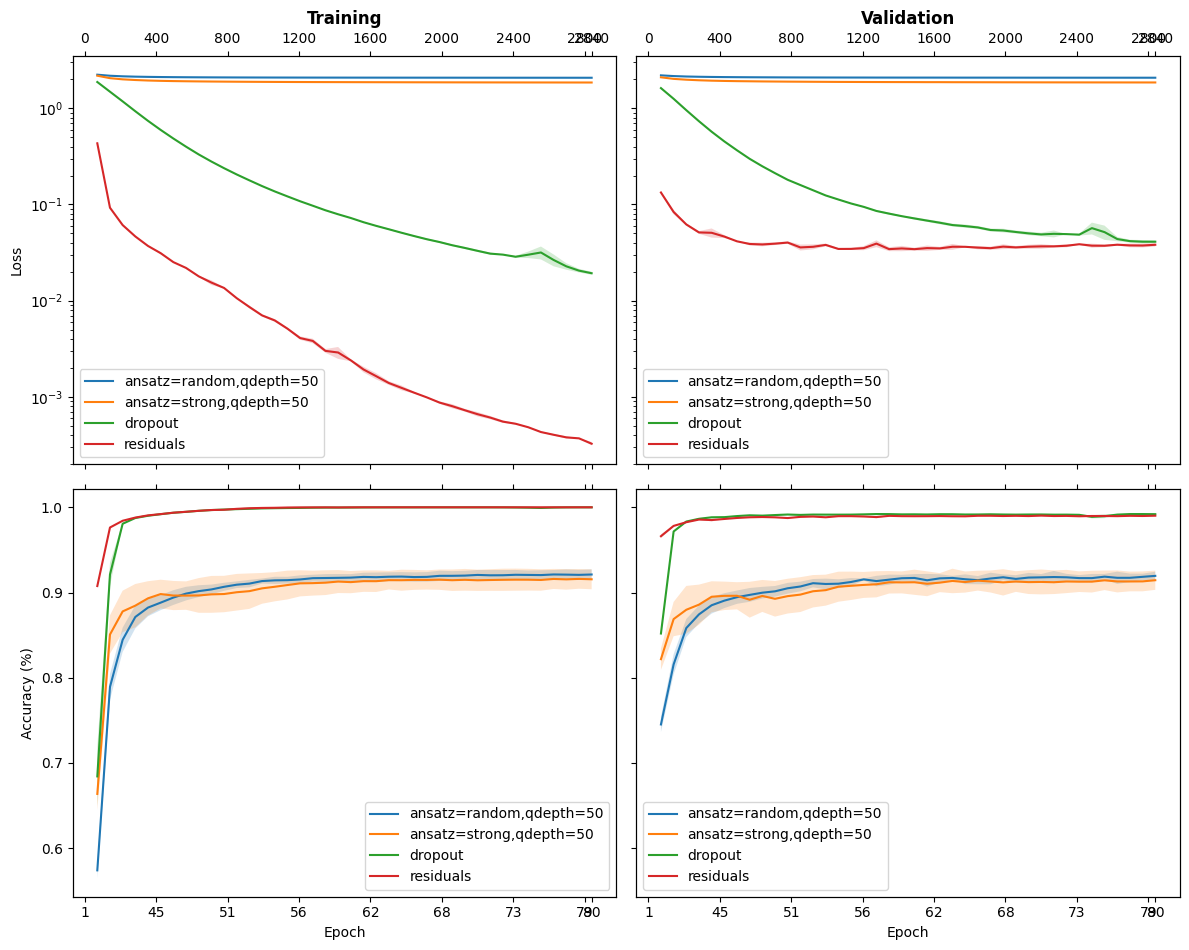

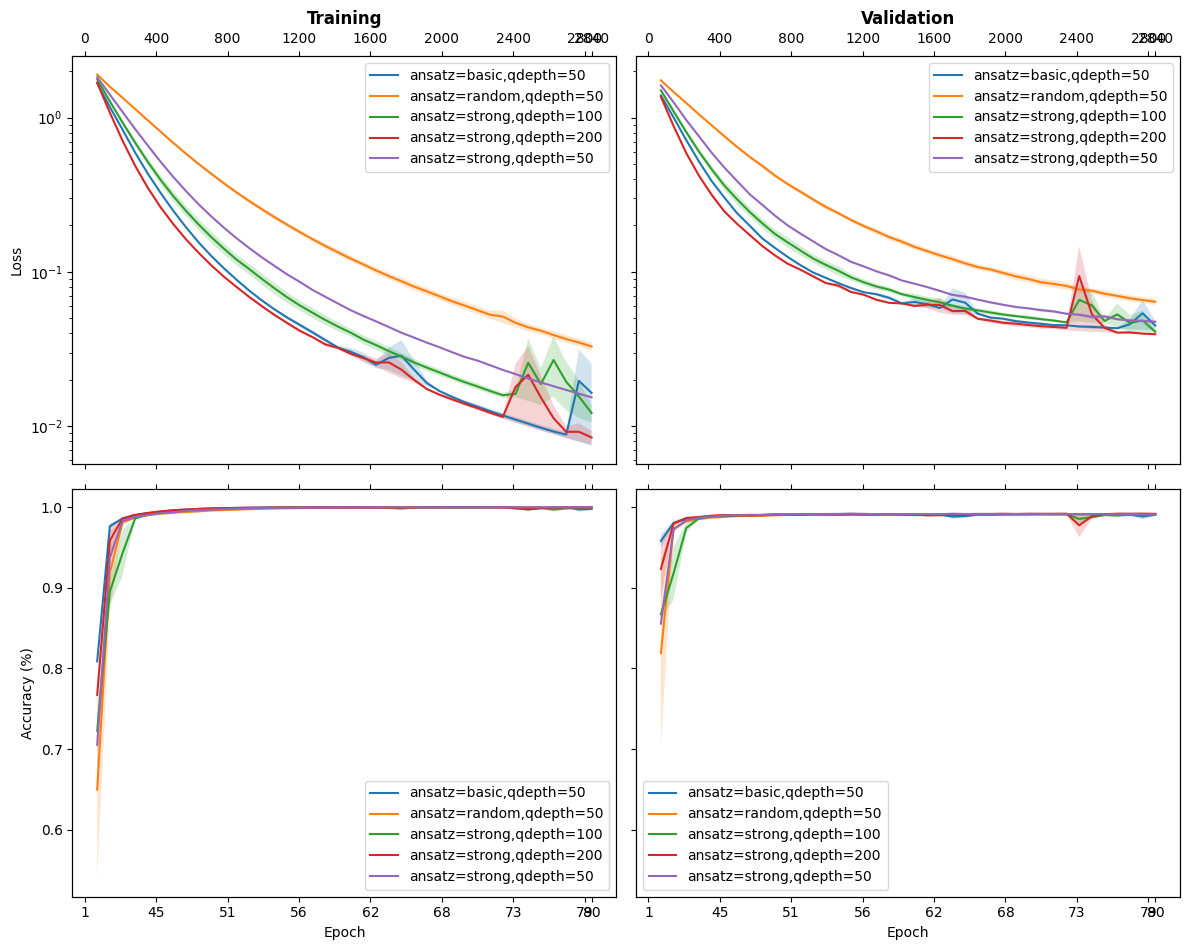

In [18]:
# The different quantum architectures with their variants

# Removing broken basic variants of HVQL for better visualization
hvql_no_basic = {k: v for k, v in models['hybrid']['hvql'].items() if "basic" not in k.lower()}

plot_models_together(models['hybrid']['hpvqm'], fig_dir=f"{output_dir}/hybrid/hpvqm", show=True)
plot_models_together(hvql_no_basic, fig_dir=f"{output_dir}/hybrid/hvql", show=True)
plot_models_together(models['hybrid']['hvqm'], fig_dir=f"{output_dir}/hybrid/hvqm", show=True)

## Quantum Models

In [11]:
models['quantum']['vqm'].keys()

dict_keys(['VQM100', 'VQM200', 'VQM50-Basic', 'VQM50-Identity', 'VQM50-NoEntangling', 'VQM50-Random', 'VQM50-Strong'])

Metric 'train/loss' not found
Metric 'train/acc' not found
Metric 'val/loss' not found
Metric 'val/acc' not found
Metric 'train/loss' not found
Metric 'train/loss' not found
Skipping model 'VQM50-Identity' due to error: No valid 'train/loss' metrics found across seeds


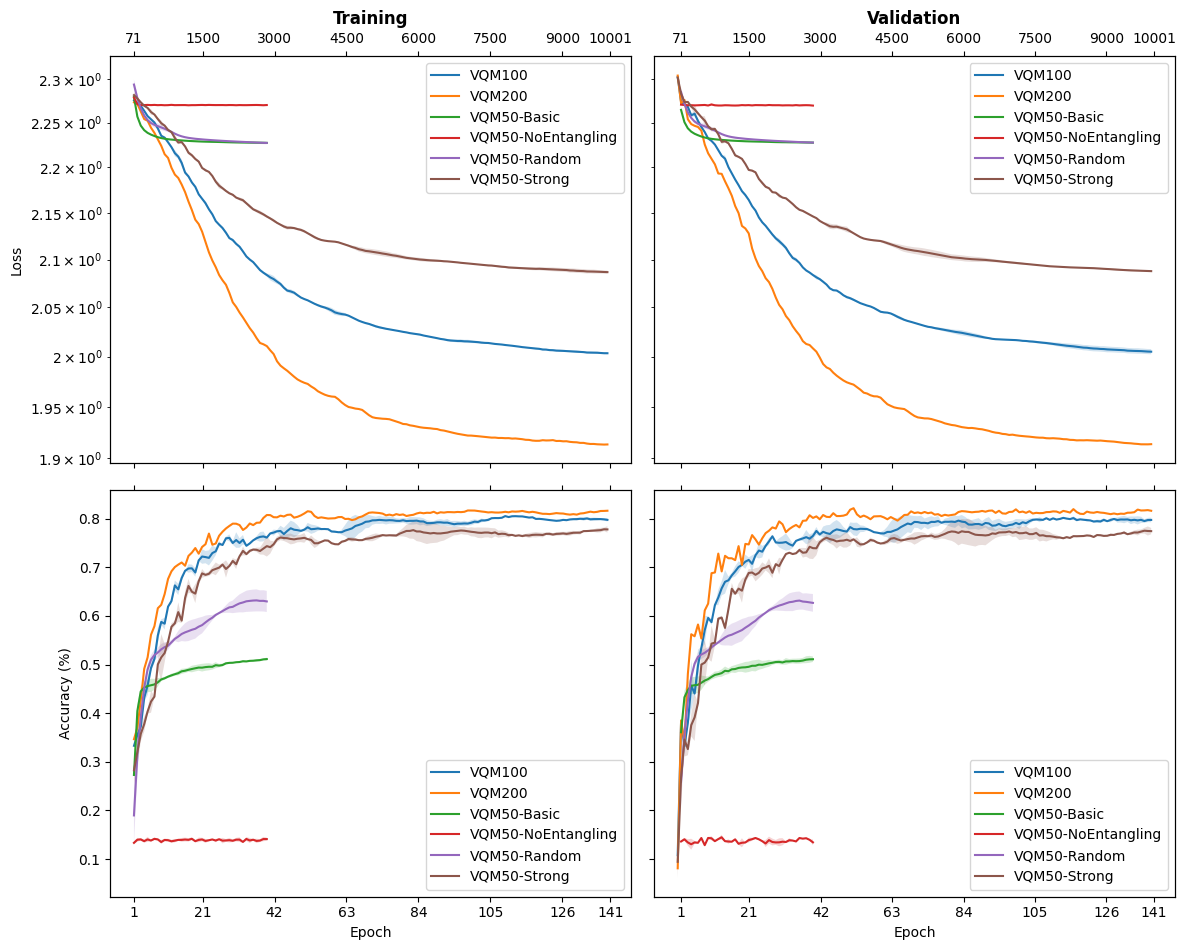

In [12]:
# All versions
# vqm_filtered = {k: v for k, v in models['quantum']['vqm'].items() if k != "VQM50-Basic" and k != "VQM50-identity" and k != "VQM50-NoEntangling"}

plot_models_together(models['quantum']['vqm'], fig_dir=f"{output_dir}/quantum/vqm", show=True)

Metric 'train/loss' not found
Metric 'train/acc' not found
Metric 'val/loss' not found
Metric 'val/acc' not found


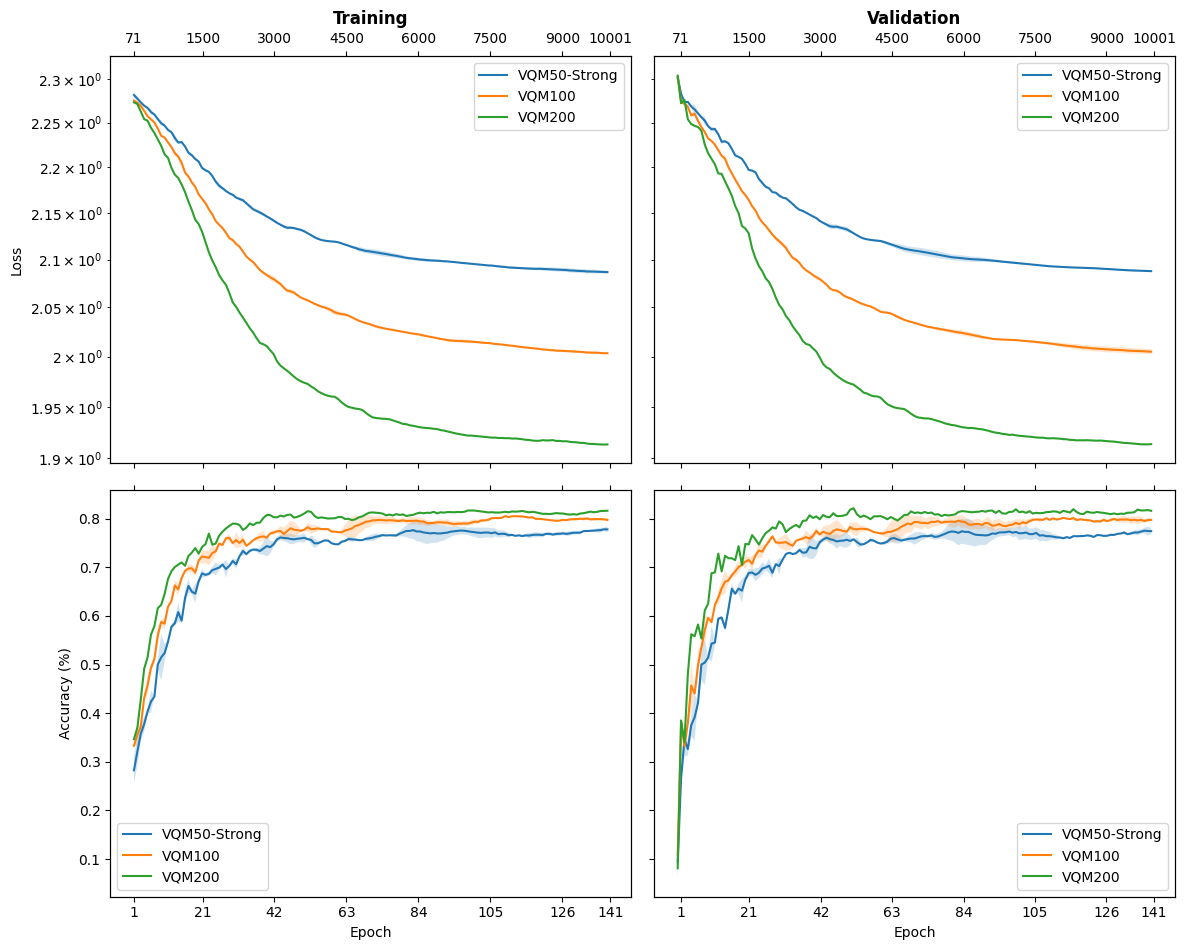

In [13]:
# Depth variants for VQM
vqm_depth_variants = {
    "VQM50-Strong": models['quantum']['vqm']['VQM50-Strong'],
    "VQM100": models['quantum']['vqm']['VQM100'],
    "VQM200": models['quantum']['vqm']['VQM200'],
}

# TODO Need to update file name
plot_models_together(vqm_depth_variants, fig_dir=f"{output_dir}/quantum/vqm", show=True)

Metric 'train/loss' not found
Metric 'train/loss' not found
Skipping model 'VQM50-Identity' due to error: No valid 'train/loss' metrics found across seeds


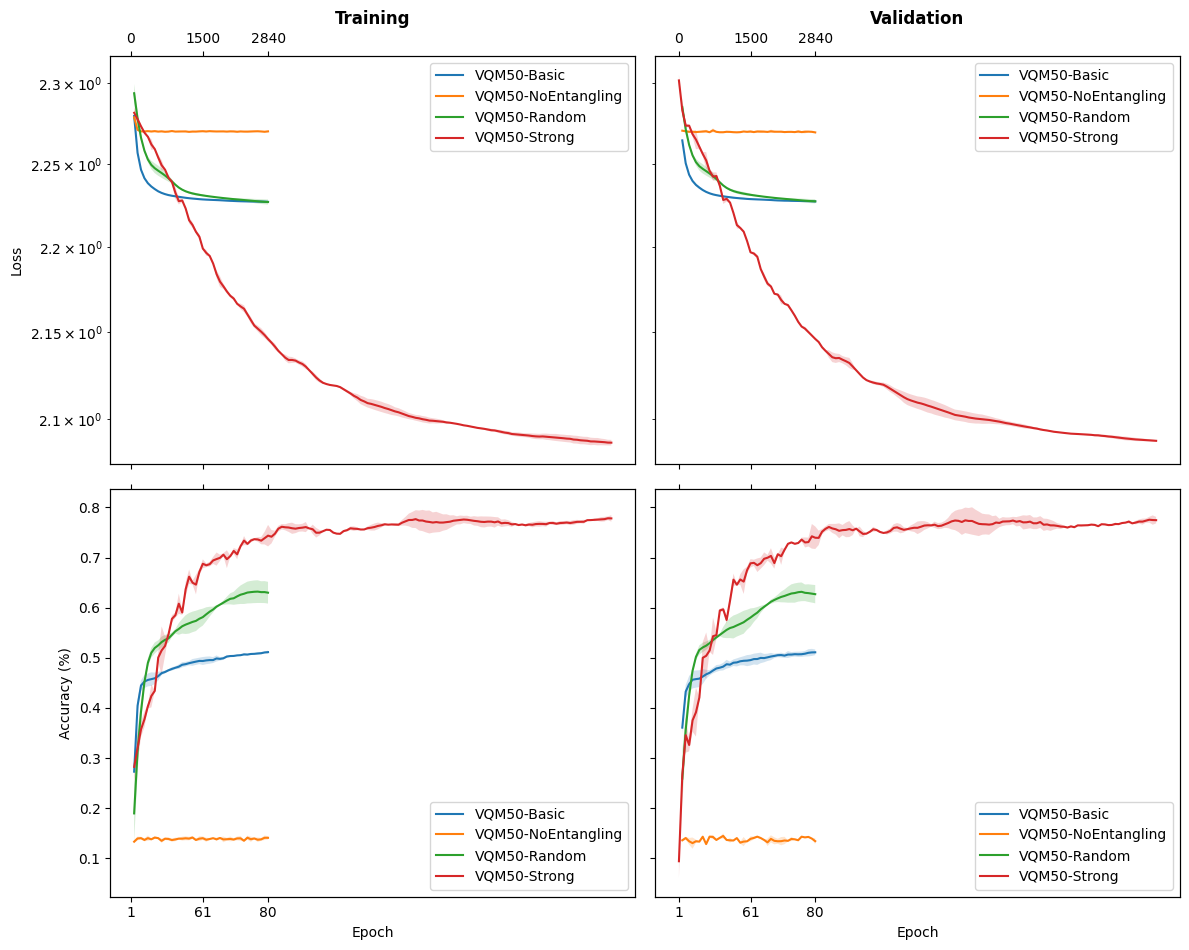

In [14]:
# Ansatz variants for VQM
vqm_ansatz_variants = {
    "VQM50-Basic": models['quantum']['vqm']['VQM50-Basic'],
    "VQM50-Identity": models['quantum']['vqm']['VQM50-Identity'],
    "VQM50-NoEntangling": models['quantum']['vqm']['VQM50-NoEntangling'],
    "VQM50-Random": models['quantum']['vqm']['VQM50-Random'],
    "VQM50-Strong": models['quantum']['vqm']['VQM50-Strong'],
}

# TODO Need to update file name
plot_models_together(vqm_ansatz_variants, fig_dir=f"{output_dir}/quantum/vqm", show=True)